# Data Quality Validation and Missing Data Handling
## Progress Review I — Individual Contribution

**Student ID:** IT25100565  
**Notebook:** `IT25100565_Data_Quality.ipynb`  
**Project:** Employee Resignation Prediction  
**Assigned Contribution:** Data Quality Validation and Missing Data Handling  

---

### 1. Purpose and Scope
This notebook provides empirical evidence for the data quality validation and missing data assessment stage of the **Employee Resignation Prediction** project:
- **Dataset Integrity:** Validating the completeness, structural integrity, and schema of the raw employee performance records.
- **Missing Value Audit:** Rigorously checking for null, missing, or unrecorded entries across all features.
- **Duplicate Detection:** Testing for full-row duplicates as well as verifying primary key uniqueness on `Employee_ID`.
- **Target Distribution Analysis:** Performing exploratory data analysis on the ground-truth target variable (`Resigned`) and examining class balance.
- **Methodological Defense:** Documenting why specific missing-value imputation strategies were not required, ensuring no unnecessary or synthetic preprocessing steps were introduced.

In [1]:
# Import required analytical and visualization libraries
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Configure pandas display settings for complete visibility per project rules
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 50)
pd.set_option("display.width", 1000)

# Configure visualization aesthetics
plt.rcParams["figure.dpi"] = 120
plt.rcParams["font.size"] = 10
sns.set_theme(style="whitegrid")

print("All required libraries imported and display settings configured successfully.")

All required libraries imported and display settings configured successfully.


In [2]:
# Resolve the repository root robustly from any launch location.
from pathlib import Path

def find_project_root(start_path: Path | None = None) -> Path:
    start = (start_path or Path.cwd()).resolve()
    for candidate in (start, *start.parents):
        if (candidate / "configs" / "feature_contract.yaml").is_file() and (candidate / "data" / "raw").is_dir():
            return candidate
    raise FileNotFoundError("Could not locate the project root.")

PROJECT_ROOT = find_project_root()
DATA_PATH = PROJECT_ROOT / "data" / "raw" / "Extended_Employee_Performance_and_Productivity_Data.csv"

# Load raw dataset into a DataFrame
df = pd.read_csv(DATA_PATH)

print(f"Dataset successfully loaded from: {DATA_PATH}")
print(f"Initial Dataset Shape: {df.shape[0]:,} rows, {df.shape[1]} columns")

# Preview the first 5 records
df.head()


Dataset successfully loaded from: E:\Yasiru's Workload\SLIIT\Y2 S1\AIML\Project\data\raw\Extended_Employee_Performance_and_Productivity_Data.csv
Initial Dataset Shape: 100,000 rows, 20 columns


,Employee_ID,Department,Gender,Age,Job_Title,Hire_Date,Years_At_Company,Education_Level,Performance_Score,Monthly_Salary,Work_Hours_Per_Week,Projects_Handled,Overtime_Hours,Sick_Days,Remote_Work_Frequency,Team_Size,Training_Hours,Promotions,Employee_Satisfaction_Score,Resigned
0,1,IT,Male,55,Specialist,2022-01-19 08:03:05.556036,2,High School,5,6750.0,33,32,22,2,0,14,66,0,2.63,False
1,2,Finance,Male,29,Developer,2024-04-18 08:03:05.556036,0,High School,5,7500.0,34,34,13,14,100,12,61,2,1.72,False
2,3,Finance,Male,55,Specialist,2015-10-26 08:03:05.556036,8,High School,3,5850.0,37,27,6,3,50,10,1,0,3.17,False
3,4,Customer Support,Female,48,Analyst,2016-10-22 08:03:05.556036,7,Bachelor,2,4800.0,52,10,28,12,100,10,0,1,1.86,False
4,5,Engineering,Female,36,Analyst,2021-07-23 08:03:05.556036,3,Bachelor,2,4800.0,38,11,29,13,100,15,9,1,1.25,False


In [3]:
# Display dataset dimensions, column names, data types, and concise schema info
print(f"Total Rows: {df.shape[0]:,}")
print(f"Total Columns: {df.shape[1]}")
print(f"Memory Usage: {df.memory_usage().sum() / (1024 * 1024):.2f} MB\n")

print("--- Column Inventory & Data Types ---")
display(df.dtypes.to_frame(name="Data_Type"))

print("\n--- DataFrame Detailed Info ---")
df.info()

Total Rows: 100,000
Total Columns: 20
Memory Usage: 14.59 MB

--- Column Inventory & Data Types ---


,Data_Type
Employee_ID,int64
Department,str
Gender,str
Age,int64
Job_Title,str
Hire_Date,str
Years_At_Company,int64
Education_Level,str
Performance_Score,int64
Monthly_Salary,float64



--- DataFrame Detailed Info ---
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 20 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   Employee_ID                  100000 non-null  int64  
 1   Department                   100000 non-null  str    
 2   Gender                       100000 non-null  str    
 3   Age                          100000 non-null  int64  
 4   Job_Title                    100000 non-null  str    
 5   Hire_Date                    100000 non-null  str    
 6   Years_At_Company             100000 non-null  int64  
 7   Education_Level              100000 non-null  str    
 8   Performance_Score            100000 non-null  int64  
 9   Monthly_Salary               100000 non-null  float64
 10  Work_Hours_Per_Week          100000 non-null  int64  
 11  Projects_Handled             100000 non-null  int64  
 12  Overtime_Hours               100000 n

In [4]:
# Comprehensive Missing Value Audit across all 20 columns
missing_counts = df.isnull().sum()
missing_percentages = (missing_counts / len(df)) * 100

missing_summary = pd.DataFrame({
    "Feature": df.columns,
    "Missing_Count": missing_counts.values,
    "Missing_Percentage (%)": missing_percentages.values
})

total_nulls = missing_counts.sum()
completeness_pct = (1.0 - (total_nulls / (df.shape[0] * df.shape[1]))) * 100

print(f"Total Missing Values across all cells: {total_nulls}")
print(f"Overall Dataset Completeness: {completeness_pct:.2f}%\n")

display(missing_summary)

Total Missing Values across all cells: 0
Overall Dataset Completeness: 100.00%



,Feature,Missing_Count,Missing_Percentage (%)
0,Employee_ID,0,0.0
1,Department,0,0.0
2,Gender,0,0.0
3,Age,0,0.0
4,Job_Title,0,0.0
5,Hire_Date,0,0.0
6,Years_At_Company,0,0.0
7,Education_Level,0,0.0
8,Performance_Score,0,0.0
9,Monthly_Salary,0,0.0


In [5]:
# Check for full-row duplicate records across all features
full_duplicates = df.duplicated().sum()

print(f"Total Duplicate Rows Detected: {full_duplicates}")

if full_duplicates == 0:
    print("Verification Result: Every row in the dataset represents a distinct observation. Zero full-row duplicates.")
else:
    print(f"Warning: Detected {full_duplicates} duplicate rows that require deduplication.")

Total Duplicate Rows Detected: 0
Verification Result: Every row in the dataset represents a distinct observation. Zero full-row duplicates.


In [6]:
# Check primary key identifier (Employee_ID) uniqueness
id_col = "Employee_ID"
total_rows = len(df)
unique_ids = df[id_col].nunique()
duplicate_ids = df[id_col].duplicated().sum()

print(f"Total Records: {total_rows:,}")
print(f"Unique '{id_col}' Count: {unique_ids:,}")
print(f"Duplicate '{id_col}' Count: {duplicate_ids}")

# Verify primary key integrity (strict 1-to-1 mapping)
is_primary_key_valid = (unique_ids == total_rows) and (duplicate_ids == 0)
print(f"\nPrimary Key Integrity Verified: {is_primary_key_valid}")
print(f"Identifier Range: Min ID = {df[id_col].min()}, Max ID = {df[id_col].max()}")

Total Records: 100,000
Unique 'Employee_ID' Count: 100,000
Duplicate 'Employee_ID' Count: 0

Primary Key Integrity Verified: True
Identifier Range: Min ID = 1, Max ID = 100000


### 2. Summary of Data Quality Findings

| Quality Dimension | Audit Target | Metric / Rule | Observed Result | Status |
| :--- | :--- | :--- | :--- | :--- |
| **Completeness** | All 20 Columns | `isnull().sum() == 0` | **0 missing cells** across 2,000,000 values | **Passed (100% Complete)** |
| **Row Uniqueness** | Entire Record | `duplicated().sum() == 0` | **0 duplicate rows** detected | **Passed (100% Distinct)** |
| **Entity Integrity** | `Employee_ID` | `nunique() == len(df)` | **100,000 unique IDs** (1 to 100,000) | **Passed (Strict Primary Key)** |
| **Schema Uniformity** | Feature Types | Numerical & Categorical Types | Clean types, no corrupted string tokens | **Passed** |

#### Key Insights for Viva Presentation:
1. **No Data Imputation Required:** Because zero values are missing, introducing artificial imputation methods (such as mean, median, mode, or iterative k-NN imputation) was not required and would have introduced unnecessary distortion.
2. **Preservation of Sample Representation:** No rows needed to be dropped due to missingness, maintaining the full statistical integrity of all 100,000 employee observations.
3. **Traceability & Linkage:** `Employee_ID` serves as a verified, uncompromised surrogate key for aligning predictions and mapping cross-validation fold registries without risk of collision.

--- Target Class Distribution Table ---


,Class,Count,Percentage (%)
0,Stayed (False / 0),89990,89.99
1,Resigned (True / 1),10010,10.01


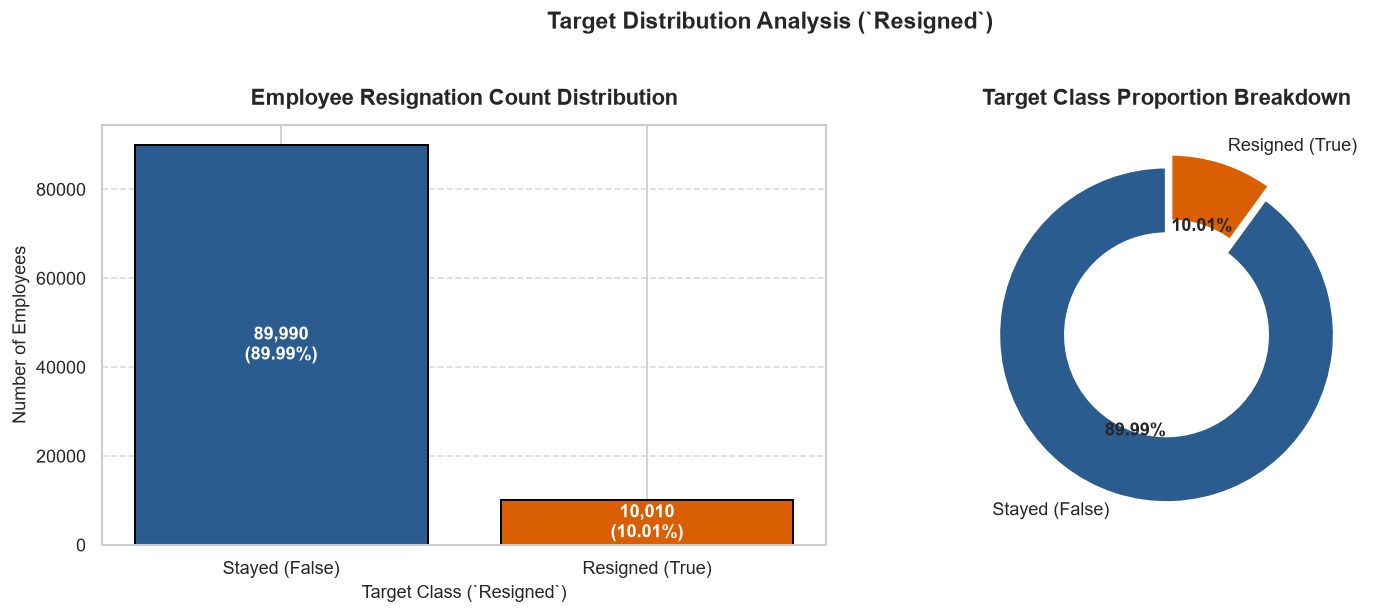

In [7]:
# Exploratory Data Analysis: Target Variable (`Resigned`) Distribution
target_col = "Resigned"
counts = df[target_col].value_counts()
percentages = df[target_col].value_counts(normalize=True) * 100

summary_target = pd.DataFrame({
    "Class": ["Stayed (False / 0)", "Resigned (True / 1)"],
    "Count": [counts[False], counts[True]],
    "Percentage (%)": [percentages[False], percentages[True]]
})

print("--- Target Class Distribution Table ---")
display(summary_target)

# Visualization: Side-by-side Countplot and Proportion Donut Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
palette = ["#2b5c8f", "#d95f02"]

# Subplot 1: Annotated Bar Chart
bars = axes[0].bar(
    ["Stayed (False)", "Resigned (True)"],
    [counts[False], counts[True]],
    color=palette,
    edgecolor="black",
    linewidth=1.2
)
axes[0].set_title("Employee Resignation Count Distribution", fontsize=13, fontweight="bold", pad=12)
axes[0].set_ylabel("Number of Employees", fontsize=11)
axes[0].set_xlabel("Target Class (`Resigned`)", fontsize=11)
axes[0].grid(axis="y", linestyle="--", alpha=0.7)

for bar in bars:
    height = bar.get_height()
    pct = (height / len(df)) * 100
    axes[0].annotate(
        f"{height:,}\n({pct:.2f}%)",
        xy=(bar.get_x() + bar.get_width() / 2, height / 2),
        ha="center", va="center",
        fontsize=11, color="white", fontweight="bold"
    )

# Subplot 2: Donut Chart
wedges, texts, autotexts = axes[1].pie(
    [counts[False], counts[True]],
    labels=["Stayed (False)", "Resigned (True)"],
    autopct="%1.2f%%",
    colors=palette,
    startangle=90,
    explode=(0, 0.08),
    wedgeprops=dict(width=0.4, edgecolor="white", linewidth=2)
)
for at in autotexts:
    at.set_fontsize(11)
    at.set_fontweight("bold")
axes[1].set_title("Target Class Proportion Breakdown", fontsize=13, fontweight="bold", pad=12)

plt.suptitle("Target Distribution Analysis (`Resigned`)", fontsize=14, fontweight="bold", y=1.02)
plt.tight_layout()
plt.show()

### 3. Target Distribution and Class Imbalance Interpretation

#### 1. Empirical Distribution & Imbalance Ratio
- **Negative Class (`Resigned = False`):** 89,990 employees (89.99%) stayed with the organization.
- **Positive Class (`Resigned = True`):** 10,010 employees (10.01%) resigned.
- **Imbalance Ratio:** Approximately **9 : 1** (or 89.99% vs. 10.01%).

#### 2. Domain and Business Realism
- In human resource analytics, voluntary employee turnover is naturally an infrequent event; typical annual voluntary resignation rates hover around 10% to 15%.
- The observed 10.01% resignation rate reflects realistic organizational retention dynamics, validating the real-world operational relevance of the dataset.

#### 3. Machine Learning Implications for Modeling & Evaluation
- **The Accuracy Fallacy:** A trivial baseline model that blindly predicts "Stayed" for every employee would achieve an apparent accuracy of **89.99%** while completely failing to identify a single resigning employee (0% recall on the minority class).
- **Metric Selection:** Consequently, overall classification accuracy is an inappropriate and deceptive evaluation metric. The modeling framework must prioritize threshold-independent discrimination metrics:
  - **PR-AUC (Precision-Recall Area Under Curve / Average Precision):** Emphasizes detection quality on the minority positive class.
  - **ROC-AUC:** Measures global ranking ability across all operating thresholds.
  - **Recall & F1-Score (Positive Class):** Quantifies the capture rate of employees at risk of leaving.
- **Algorithmic Handling in Downstream Modeling:** Models must incorporate class weighting (e.g., `scale_pos_weight` in XGBoost/LightGBM/CatBoost or balanced class weights) and stratified sampling across cross-validation folds to prevent negative-class dominance.

### 4. Final Conclusions and Viva Defense

#### 1. Dataset Completeness
The raw dataset of **100,000 records across 20 features** possesses 100% completeness:
- Every cell across all 2,000,000 data points contains valid, non-null observations.
- Primary entity resolution is preserved with exactly 100,000 unique `Employee_ID` values.
- No full-row duplicate records exist.

#### 2. Justification for No Missing-Value Treatment
- Standard data preparation pipelines typically include imputation strategies such as mean/median substitution, k-Nearest Neighbors (k-NN), or Multiple Imputation by Chained Equations (MICE).
- In this project, **no imputation was conducted because no data points are missing**.
- Applying artificial missing-value handling or synthetically altering complete records would violate the integrity of the data and introduce unnecessary bias.

#### 3. Why Data Quality Checks Matter Before Preprocessing
Conducting rigorous data quality validation prior to feature preprocessing provides essential project safeguards:
- **Prevents Downstream Pipeline Failures:** Ensures categorical encoders (One-Hot, Ordinal) and numerical scalers (`StandardScaler`, `MinMaxScaler`) do not encounter unhandled NaNs or raise runtime exceptions.
- **Eliminates Hidden Leakage & Data Corruption:** Confirms entity integrity and prevents duplicate records from artificially leaking across cross-validation training and validation splits.
- **Informs Metric and Loss Formulation:** Identifying the ~90:10 (9:1) class imbalance upfront informs the selection of proper evaluation metrics (PR-AUC, ROC-AUC, Brier score) and training objectives before any model training begins.